<div style="background-color:#b2c7db; padding:20px; border-radius:10px; border-left:8px solid #355473;">

<h2 style="margin-top:0; color:#355473;"><b>Programming for Data Science</b></h2>
<h4 style="margin-top:-5px; color:#297681;">LCD &nbsp;—&nbsp; Teachers: Carina Albuquerque and Dinis Gaspar &nbsp;—&nbsp; 2026/2027</h4>
<br>

<h1 style="margin-bottom:0; color:#355473;"><b>"What makes a music artist 
successful?” "</b></h1>


<h3 style="color:#355473;"><b>Group 15 - Team Members</b></h3>

<table style="color:#355473;">
<thead>
<tr>
<th style="color:#355473; text-align:left;">Name</th>
<th style="color:#355473; text-align:left;">Student Number</th>
</tr>
</thead>
<tbody>
<tr>
<td>João Umbelino</td>
<td>20251309</td>
</tr>
<tr>
<td>Mariana Monteiro</td>
<td>20251290</td>
</tr>
<tr>
<td>Martim Violante</td>
<td>20251310</td>
</tr>
<tr>
<td>Rafael Portela</td>
<td>20251361</td>
</tr>
</tbody>
</table>

<br>
</div>

In [122]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import warnings
import plotly.graph_objects as go
import plotly.express as px
from plotly.subplots import make_subplots
warnings.filterwarnings("ignore")

In [123]:
data = pd.read_csv('artist_streams.csv', skipfooter = 1, index_col = 0)

artist_df = data.copy()

display(artist_df.head())
artist_df.shape

,Artist Name,Sex,Country of Origin,Primary Language,Primary Genre,Artist Type,Debut Year,Total Streams,Lead Streams,Feature Streams,Solo Streams,Collaborative Streams,Update Date,Year
Artist ID,,,,,,,,,,,,,,
0,Drake,Male,Canada,English,Hip-Hop,Solo,2006.0,137492.1,94851.1,42640.9,53323.9,84168.2,2026-07-01 00:00:00,2026.0
1,Taylor Swift,Female,United States,English,Pop,Solo,2006.0,127861.0,126177.3,1683.8,113421.5,14439.5,2026-07-01 00:00:00,2026.0
2,Bad Bunny,Male,United States,Spanish,Reggaeton,Solo,2013.0,125899.8,82189.3,43710.5,48887.0,77012.8,2026-07-01 00:00:00,2026.0
3,The Weeknd,Male,Canada,English,R&B,Solo,2009.0,95703.2,77189.4,18513.8,51020.0,44683.2,2026-07-01 00:00:00,2026.0
4,Justin Bieber,Male,Canada,English,Pop,Solo,2009.0,78104.4,48316.2,29788.2,29638.3,48466.1,2026-07-01 00:00:00,2026.0


(510, 14)

In [124]:
#### MUDAR VER REVER SLSA


display(artist_df[artist_df['Artist Name'].isna()])   # linha só com o ID
artist_df = artist_df.dropna(subset=['Artist Name'])  # sem informação nenhuma -> removida

,Artist Name,Sex,Country of Origin,Primary Language,Primary Genre,Artist Type,Debut Year,Total Streams,Lead Streams,Feature Streams,Solo Streams,Collaborative Streams,Update Date,Year
Artist ID,,,,,,,,,,,,,,


In [125]:
artist_df.info(memory_usage="deep")

<class 'pandas.DataFrame'>
Index: 510 entries, 0 to 499
Data columns (total 14 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Artist Name            510 non-null    str    
 1   Sex                    486 non-null    str    
 2   Country of Origin      510 non-null    str    
 3   Primary Language       510 non-null    str    
 4   Primary Genre          510 non-null    str    
 5   Artist Type            510 non-null    str    
 6   Debut Year             510 non-null    float64
 7   Total Streams          505 non-null    float64
 8   Lead Streams           504 non-null    float64
 9   Feature Streams        499 non-null    float64
 10  Solo Streams           506 non-null    float64
 11  Collaborative Streams  509 non-null    float64
 12  Update Date            510 non-null    str    
 13  Year                   510 non-null    float64
dtypes: float64(7), str(7)
memory usage: 233.4 KB


In [126]:
print(f"Rows: {len(artist_df)}")
print(f"Fully duplicated rows: {artist_df.duplicated().sum()}")
print(f"Duplicated Artist IDs: {artist_df.index.duplicated().sum()}")
print(f"Duplicated Artist Names: {artist_df['Artist Name'].duplicated().sum()}")

# Show the duplicated rows side by side
artist_df[artist_df.duplicated(keep=False)].head()

Rows: 510
Fully duplicated rows: 10
Duplicated Artist IDs: 10
Duplicated Artist Names: 10


,Artist Name,Sex,Country of Origin,Primary Language,Primary Genre,Artist Type,Debut Year,Total Streams,Lead Streams,Feature Streams,Solo Streams,Collaborative Streams,Update Date,Year
Artist ID,,,,,,,,,,,,,,
45,Linkin Park,NaN,United States,English,Rock,Group,2000.0,33224.7,31426.6,1798.1,30151.2,3073.5,2026-07-01 00:00:00,2026.0
45,Linkin Park,NaN,United States,English,Rock,Group,2000.0,33224.7,31426.6,1798.1,30151.2,3073.5,2026-07-01 00:00:00,2026.0
140,Fleetwood Mac,NaN,United Kingdom,English,Rock,Group,1967.0,16577.5,16577.5,NaN,16567.4,10.1,2026-07-01 00:00:00,2026.0
140,Fleetwood Mac,NaN,United Kingdom,English,Rock,Group,1967.0,16577.5,16577.5,NaN,16567.4,10.1,2026-07-01 00:00:00,2026.0
218,John Mayer,Male,United States,English,Pop,Solo,1999.0,13208.3,12134.4,1076.8,11821.4,1386.9,2026-07-01 00:00:00,2026.0


In [127]:
artist_df = artist_df.drop_duplicates().copy() #Tiramos as rows do ID (que correspondem às rows exatamente iguais)
artist_df.shape

(500, 14)

## MISSING

In [128]:
total_missing=artist_df.isnull().sum()
display(total_missing)
total_missing.sum()

Artist Name               0
Sex                      22
Country of Origin         0
Primary Language          0
Primary Genre             0
Artist Type               0
Debut Year                0
Total Streams             5
Lead Streams              6
Feature Streams           9
Solo Streams              4
Collaborative Streams     1
Update Date               0
Year                      0
dtype: int64

np.int64(47)

In [129]:
missing_percent = (total_missing / len(artist_df)) * 100

missing_summary = pd.DataFrame({
    'Missing Values': total_missing,
    'Percentage (%)': missing_percent.round(2)
})

missing_summary[missing_summary['Missing Values'] > 0]

,Missing Values,Percentage (%)
Sex,22,4.4
Total Streams,5,1.0
Lead Streams,6,1.2
Feature Streams,9,1.8
Solo Streams,4,0.8
Collaborative Streams,1,0.2


## TOTAL STREAMS


inconsistencys in total streams formula

**Missing streams.** As stated in the project description, Total Streams = Solo + Collaborative = Lead + Feature. Instead of deleting these artists or using the mean, each missing value is calculated from the other stream columns of the same artist, which gives the real value.

In one case the calculated Feature Streams was slightly negative (−13.8), because Lead + Feature does not exactly match the Total in the data. Since streams cannot be negative, it was set to 0.

In [130]:
#??????????????????????????????????????? Check how well each identity holds in the complete rows
diff_solo = artist_df['Solo Streams'] + artist_df['Collaborative Streams'] - artist_df['Total Streams']
diff_lead = artist_df['Lead Streams'] + artist_df['Feature Streams'] - artist_df['Total Streams']

# Number of artists where each formula gives exactly the Total
print(f"Solo + Collaborative = Total in {(diff_solo.round(2) == 0).sum()} of {diff_solo.notna().sum()} artists")
print(f"Lead + Feature = Total in {(diff_lead.round(2) == 0).sum()} of {diff_lead.notna().sum()} artists")

Solo + Collaborative = Total in 490 of 490 artists
Lead + Feature = Total in 74 of 480 artists


In [131]:
artist_df['Total Streams'] = artist_df['Total Streams'].fillna(artist_df['Solo Streams'] + artist_df['Collaborative Streams'])
artist_df['Solo Streams'] = artist_df['Solo Streams'].fillna(artist_df['Total Streams'] - artist_df['Collaborative Streams'])
artist_df['Collaborative Streams'] = artist_df['Collaborative Streams'].fillna(artist_df['Total Streams'] - artist_df['Solo Streams'])
artist_df['Lead Streams'] = artist_df['Lead Streams'].fillna(artist_df['Total Streams'] - artist_df['Feature Streams']).clip(lower=0)
artist_df['Feature Streams'] = artist_df['Feature Streams'].fillna(artist_df['Total Streams'] - artist_df['Lead Streams']).clip(lower=0)  # clip(lower=0): any negative value becomes 0 (Lead + Feature is only approximately equal to Total)

## SEX

In [132]:
display(artist_df.groupby('Artist Type')['Sex'].value_counts(dropna=False))
artist_df['Sex'] = artist_df['Sex'].fillna('Band')

Artist Type  Sex   
Group        Male       99
             NaN        22
             Female      6
Solo         Male      291
             Female     82
Name: count, dtype: int64

In [133]:
display(artist_df.isnull().sum())
artist_df.shape

Artist Name              0
Sex                      0
Country of Origin        0
Primary Language         0
Primary Genre            0
Artist Type              0
Debut Year               0
Total Streams            0
Lead Streams             0
Feature Streams          0
Solo Streams             0
Collaborative Streams    0
Update Date              0
Year                     0
dtype: int64

(500, 14)

### 4.1.2 - Descriptive Artist Analysis

#### a) Total Unique Artists and Pop Artists Count
In this section, we determine the total number of unique artists present in the cleaned dataset and calculate how many of those artists are primarily categorized under the **Pop** genre.

In [134]:
total_unique_artists = artist_df['Artist Name'].nunique()

pop_artists_count = (artist_df['Primary Genre'] == 'Pop').sum()

print(f"Total unique artists: {total_unique_artists}")
print(f"Total Pop artists: {pop_artists_count}")

Total unique artists: 500
Total Pop artists: 102


1. **`nunique()` on `Artist Name`:** Used to explicitly calculate distinct artist entries rather than simply counting rows, ensuring strict compliance with the question prompt.
2. **Direct Boolean Filtering (`== 'Pop'`):** Creates a boolean mask that identifies rows where `Primary Genre` is `'Pop'`, and `.sum()` adds up all the `True` occurrences to get the total count.

### 4.1.2 B) -RAFAEL


Primary Genre
Hip-Hop      115
Pop          102
Rock          60
Reggaeton     43
R&B           31
Name: count, dtype: int64


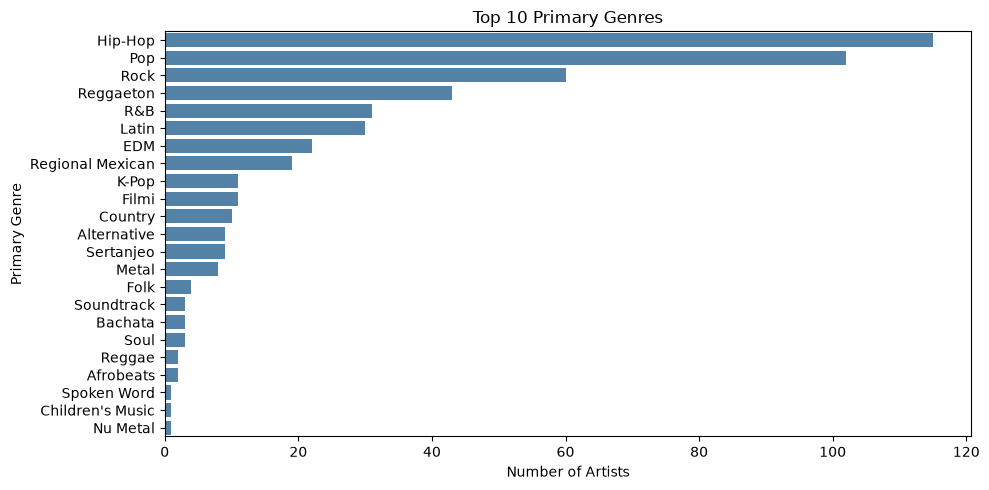

In [135]:
# Most common primary genre
genre_counts = artist_df['Primary Genre'].value_counts()
print(genre_counts.head())

plt.figure(figsize=(10, 5))
sns.barplot(x=genre_counts.values, y=genre_counts.index, color='steelblue')
plt.title('Top 10 Primary Genres')
plt.xlabel('Number of Artists')
plt.ylabel('Primary Genre')
plt.tight_layout()
plt.show()

The most common primary genre is Hip-Hop, with 115 artists.

### 4.1.2 C) - Mariana - What is the most common country of origin?

In [ ]:
country_counts = artist_df['Country of Origin'].value_counts()
print(country_counts.head())
print()
print(f"Most common country of origin among artists: {country_counts.index[0]}")
print(f"Number of artists from {country_counts.index[0]}: {country_counts.values[0]}")

Country of Origin
United States     265
United Kingdom     55
Mexico             27
Canada             18
Colombia           16
Name: count, dtype: int64

Most common country of origin: United States
Number of artists from United States: 265


The most common country of origin is the **United States, with 265 artists**.

### 4.1.2 D) -JOÃO


What are the top 3 most common languages among artist?

In [137]:
artist_df['Primary Language'].value_counts()

Primary Language
English       340
Spanish       105
Portuguese     15
Korean         11
Hindi          11
German          7
French          4
Italian         3
Tamil           2
Urdu            1
Punjabi         1
Name: count, dtype: int64

From this value count we already know they are English, Spanish and Portuguese, but we will now see it on a bar plot

In [138]:
fig = px.histogram(artist_df, x = 'Primary Language', title = 'Primary Language Counts', height=600, text_auto=True, color_discrete_sequence=["#0BB910"])
fig.show()

As we can verify, English is the language with the most artists, with 340 artist, next is spanish with 105 artists and thirdly portuguese with 15.